# Week3_ex1 Analysis — Nominal vs Equivalent π for a 300 km Line

Deep dive on Examples 5.2, 5.4 and 5.10 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.). Given per-kilometre data, `create_line_from_parameters` multiplies by the length and builds a **nominal π**:

$$Z = z\,l, \qquad \frac{Y}{2} = \frac{y\,l}{2}$$

A long line is really a distributed circuit, and the π that reproduces its terminal behaviour exactly is the **equivalent π**:

$$Z' = Z_c \sinh(\gamma l) = z\,l\,\frac{\sinh(\gamma l)}{\gamma l}, \qquad \frac{Y'}{2} = \frac{\tanh(\gamma l/2)}{Z_c} = \frac{y\,l}{2}\,\frac{\tanh(\gamma l/2)}{\gamma l/2}, \qquad Z_c = \sqrt{z/y},\;\; \gamma = \sqrt{z\,y}$$

For the Example 5.2 line ($z = 0.0165 + j0.3306\ \Omega$/km, $y = j4.674\ \mu$S/km, $l = 300$ km) $\gamma l \approx 0.373$, so the series correction $\sinh(\gamma l)/\gamma l$ is about 0.977 and the shunt correction $\tanh(\gamma l/2)/(\gamma l/2)$ about 1.012. Both corrections grow roughly with $(\gamma l)^2$. Two questions follow: which of the two π models the PowerWorld cases store, and at what length the nominal π stops being good enough for a planning study.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp

# 1. Line constants: per-km data from Example 5.2 (textbook), case data read once from PowerWorld Simulator
#    (Run Mode, Model Explorer > Network > Branches Input; Simulator Options > Power Flow Solution > General)
S_BASE = 500.0
V_KV = 765.0
F_HZ = 60.0
Z_BASE = V_KV**2 / S_BASE
Z_KM = 0.0165 + 0.3306j       # ohm/km
Y_KM = 4.674e-6j              # S/km
LENGTH = 300.0                # km
MVA_TOL = 0.5
PW_LINE = {"Example 5.10 line": (0.0, 0.08279, 1.66050), "Example 5.4 line": (0.0, 0.08290, 1.66090)}


def pi_model(length, kind, z=Z_KM, y=Y_KM):
    """Series impedance Z [ohm] and total shunt admittance Y [S] of a line, nominal or equivalent pi."""
    if kind == "nominal":
        return z * length, y * length
    gl = np.sqrt(z * y) * length
    zc = np.sqrt(z / y)
    return zc * np.sinh(gl), 2 * np.tanh(gl / 2) / zc


def add_line(net, f, t, Z, Y, keep_r=True):
    """Add a pi section; pandapower splits c_nf and g_us between the two ends."""
    return pp.create_line_from_parameters(
        net, f, t, length_km=1.0, r_ohm_per_km=Z.real if keep_r else 0.0, x_ohm_per_km=Z.imag,
        c_nf_per_km=Y.imag / (2 * np.pi * F_HZ) * 1e9, g_us_per_km=Y.real * 1e6 if keep_r else 0.0,
        max_i_ka=10.0)


gl = np.sqrt(Z_KM * Y_KM) * LENGTH
pd.DataFrame({
    "Quantity": ["gamma * l", "Zc [ohm]", "sinh(gl) / gl", "tanh(gl/2) / (gl/2)"],
    "Value": [f"{gl:.4f}", f"{np.sqrt(Z_KM / Y_KM):.2f}", f"{np.sinh(gl) / gl:.4f}",
              f"{np.tanh(gl / 2) / (gl / 2):.4f}"],
})

,Quantity,Value
0,gamma * l,0.0093+0.3730j
1,Zc [ohm],266.04-6.63j
2,sinh(gl) / gl,0.9770+0.0011j
3,tanh(gl/2) / (gl/2),1.0118-0.0006j


In [2]:
# 2. The two pi models next to what the PowerWorld cases store, all on the 500 MVA base
rows = []
for kind in ["nominal", "equivalent"]:
    Z, Y = pi_model(LENGTH, kind)
    rows.append({"Model": f"{kind} pi from Example 5.2", "R [pu]": Z.real / Z_BASE, "X [pu]": Z.imag / Z_BASE,
                 "G [pu]": Y.real * Z_BASE, "B [pu]": Y.imag * Z_BASE})
for name, (r, x, b) in PW_LINE.items():
    rows.append({"Model": f"PowerWorld, {name}", "R [pu]": r, "X [pu]": x, "G [pu]": 0.0, "B [pu]": b})
params = pd.DataFrame(rows).set_index("Model")

ref = params.loc["PowerWorld, Example 5.10 line"]
params["X vs 5.10 case [%]"] = (params["X [pu]"] / ref["X [pu]"] - 1) * 100
params["B vs 5.10 case [%]"] = (params["B [pu]"] / ref["B [pu]"] - 1) * 100
params.round(5)

,R [pu],X [pu],G [pu],B [pu],X vs 5.10 case [%],B vs 5.10 case [%]
Model,,,,,,
nominal pi from Example 5.2,0.00423,0.08474,0.00000,1.64120,2.35130,-1.16200
equivalent pi from Example 5.2,0.00404,0.08279,0.00098,1.66049,0.00119,-0.00043
"PowerWorld, Example 5.10 line",0.00000,0.08279,0.00000,1.66050,0.00000,0.00000
"PowerWorld, Example 5.4 line",0.00000,0.08290,0.00000,1.66090,0.13287,0.02409


In [3]:
# 3. Flow check: Example 5.10 with both capacitors in service at 3000 MW, the line swapped between models
#    (the capacitors carry no fitted values, and the heavy load makes the line impedance count)
X_CAP = -0.01240
PW_3000 = {"Bus B voltage [kV]": 749.022, "Bus B angle [deg]": -21.36, "Three voltage [kV]": 773.370,
           "Three angle [deg]": 4.22, "Four voltage [kV]": 751.275, "Four angle [deg]": -25.80,
           "Slack P [MW]": 3000.01, "Slack Q [Mvar]": 330.64}
DISPLAY = [5e-4, 5e-3] * 3 + [MVA_TOL, MVA_TOL]


def build_510(kind, p_mw=3000.0, q_mvar=0.0):
    net = pp.create_empty_network(f_hz=F_HZ, sn_mva=S_BASE)
    b = [pp.create_bus(net, vn_kv=V_KV) for _ in range(4)]   # index = PowerWorld number - 1
    pp.create_ext_grid(net, b[0], vm_pu=1.0)
    Z, Y = pi_model(LENGTH, kind)
    add_line(net, b[2], b[3], Z, Y, keep_r=False)            # the case drops R and G
    for f, t in [(b[0], b[2]), (b[3], b[1])]:
        pp.create_impedance(net, f, t, rft_pu=0.0, xft_pu=X_CAP, sn_mva=S_BASE)
    pp.create_load(net, b[1], p_mw=p_mw, q_mvar=q_mvar)
    pp.runpp(net, numba=False)
    return net


def results(net):
    out = {}
    for i, name in [(1, "Bus B"), (2, "Three"), (3, "Four")]:
        out[f"{name} voltage [kV]"] = net.res_bus.vm_pu.iat[i] * V_KV
        out[f"{name} angle [deg]"] = net.res_bus.va_degree.iat[i]
    out["Slack P [MW]"] = net.res_ext_grid.p_mw.iat[0]
    out["Slack Q [Mvar]"] = net.res_ext_grid.q_mvar.iat[0]
    return pd.Series(out)


def residual_band(kind):
    base = results(build_510(kind))
    moved = [results(build_510(kind, 3000.0 + dp, dq)) - base
             for dp, dq in [(MVA_TOL, 0.0), (-MVA_TOL, 0.0), (0.0, MVA_TOL), (0.0, -MVA_TOL)]]
    return pd.concat(moved, axis=1).abs().max(axis=1)


cmp = pd.DataFrame({"PowerWorld": pd.Series(PW_3000),
                    "H1 nominal pi": results(build_510("nominal")),
                    "H2 equivalent pi": results(build_510("equivalent"))})
cmp["Tolerance"] = np.maximum(DISPLAY, residual_band("equivalent"))
for h in ["H1", "H2"]:
    col = [c for c in cmp.columns if c.startswith(h)][0]
    cmp[f"{h} error"] = (cmp[col] - cmp["PowerWorld"]).abs()
    cmp[f"{h} within"] = cmp[f"{h} error"] <= cmp["Tolerance"]
assert cmp["H2 within"].all() and not cmp["H1 within"].all()
cmp.round(3)

,PowerWorld,H1 nominal pi,H2 equivalent pi,Tolerance,H1 error,H1 within,H2 error,H2 within
Bus B voltage [kV],749.022,745.362,749.023,0.058,3.660,False,0.001,True
Bus B angle [deg],-21.360,-22.223,-21.365,0.005,0.863,False,0.005,True
Three voltage [kV],773.370,774.532,773.371,0.013,1.162,False,0.001,True
Three angle [deg],4.220,4.214,4.220,0.005,0.006,False,0.000,True
Four voltage [kV],751.275,747.647,751.275,0.067,3.628,False,0.000,True
Four angle [deg],-25.800,-26.704,-25.802,0.005,0.904,False,0.002,True
Slack P [MW],3000.010,3000.000,3000.000,0.500,0.010,True,0.010,True
Slack Q [Mvar],330.640,392.024,330.666,0.681,61.384,False,0.026,True


## Hypothesis 1 — the cases store a nominal π built from the per-km data

If PowerWorld had simply multiplied the Example 5.2 constants by 300 km, its line would carry $X = 0.08474$ pu and $B = 1.64120$ pu, and swapping that line into Example 5.10 should reproduce PowerWorld at 3000 MW.

**Verdict: rejected.** The stored reactance is 2.35 % below the nominal value and the susceptance 1.16 % above it, which are exactly the sinh and tanh corrections. In the flow check the nominal line leaves Bus B 3.66 kV low, opens the end-to-end angle by a further 0.86°, and asks the slack for 61 Mvar more than PowerWorld does. Every voltage, angle and reactive power lands far outside tolerance; only the slack P agrees, because the line is lossless in both versions.

## Hypothesis 2 — the cases store the equivalent π with R and G dropped

The equivalent π gives $X = 0.08279$ pu and $B = 1.66049$ pu, which matches the Example 5.10 Branches Input to the last digit shown. Its resistance (0.00404 pu) and shunt conductance are set to zero in the case, so the same model with `keep_r=False` should reproduce the flows.

**Verdict: accepted.** All eight quantities fall inside tolerance, the largest miss being 0.005° on the Bus B angle. The Example 5.4 file stores $X = 0.08290$ pu, 0.13 % above the equivalent π reactance and close to its magnitude $|Z'| = 0.08289$ pu, so that case seems to have been built from $|Z'|$ rather than its imaginary part. The gap is far too small to change any result, which is why Week3_ex1 still matches its own case.

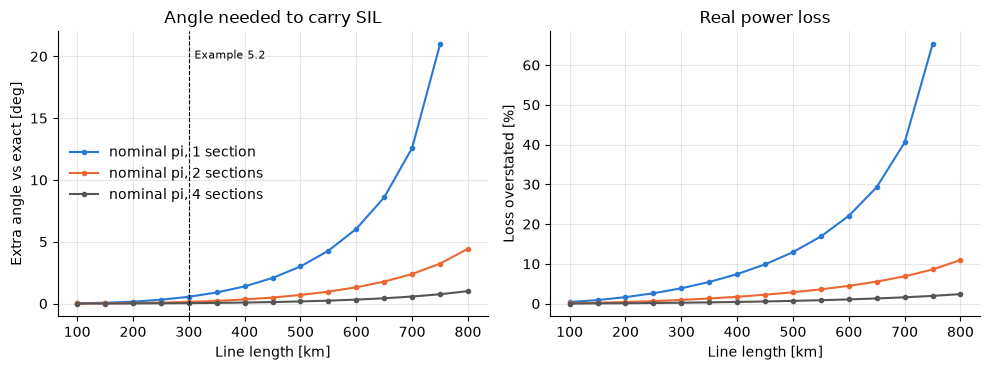

In [4]:
# 4. How the nominal pi error grows with length, and how much splitting the line buys back
# Reference: one equivalent pi with R and G kept (exact for the distributed line at its terminals).
# Both ends are held at 1.0 pu and the line delivers its surge impedance loading, so every length is
# compared at the same operating point a planner would treat as "normal" for this voltage class.
SIL_MW = V_KV**2 / abs(np.sqrt(Z_KM / Y_KM))


def run_line(length, kind, sections):
    net = pp.create_empty_network(f_hz=F_HZ, sn_mva=S_BASE)
    buses = [pp.create_bus(net, vn_kv=V_KV) for _ in range(sections + 1)]
    pp.create_ext_grid(net, buses[0], vm_pu=1.0)
    Z, Y = pi_model(length / sections, kind)
    for f, t in zip(buses[:-1], buses[1:]):
        add_line(net, f, t, Z, Y)
    pp.create_load(net, buses[-1], p_mw=SIL_MW)
    pp.create_gen(net, buses[-1], p_mw=0.0, vm_pu=1.0)       # receiving end held at 765 kV
    try:
        pp.runpp(net, numba=False)
    except pp.LoadflowNotConverged:
        return {"angle": np.nan, "q_recv": np.nan, "loss": np.nan}
    return {"angle": net.res_bus.va_degree.iat[-1], "q_recv": net.res_gen.q_mvar.iat[0],
            "loss": net.res_line.pl_mw.sum()}


SECTIONS = [1, 2, 4]
rows = []
for length in range(100, 801, 50):
    exact = run_line(length, "equivalent", 1)
    row = {"Length [km]": length, "Exact angle [deg]": exact["angle"], "Exact loss [MW]": exact["loss"]}
    for n in SECTIONS:
        nom = run_line(length, "nominal", n)
        row[f"Angle error, {n} section(s) [deg]"] = nom["angle"] - exact["angle"]
        row[f"Q error, {n} section(s) [Mvar]"] = nom["q_recv"] - exact["q_recv"]
        row[f"Loss error, {n} section(s) [%]"] = (nom["loss"] / exact["loss"] - 1) * 100
    rows.append(row)
sweep = pd.DataFrame(rows)

# Splitting into n sections should cut the error by roughly n^2, since it scales with (gamma * section)^2
at_400 = sweep.set_index("Length [km]").loc[400]
ratio = at_400["Angle error, 1 section(s) [deg]"] / at_400["Angle error, 2 section(s) [deg]"]
assert 3.5 < ratio < 4.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
colors = {1: "#2a78d6", 2: "#eb6834", 4: "#555555"}
for n in SECTIONS:
    ax1.plot(sweep["Length [km]"], -sweep[f"Angle error, {n} section(s) [deg]"], marker="o", ms=3,
             color=colors[n], label=f"nominal pi, {n} section" + ("s" if n > 1 else ""))
    ax2.plot(sweep["Length [km]"], sweep[f"Loss error, {n} section(s) [%]"], marker="o", ms=3, color=colors[n])
ax1.axvline(LENGTH, color="black", lw=0.8, ls="--")
ax1.text(LENGTH + 10, ax1.get_ylim()[1] * 0.9, "Example 5.2", fontsize=8)
ax1.set(xlabel="Line length [km]", ylabel="Extra angle vs exact [deg]", title="Angle needed to carry SIL")
ax2.set(xlabel="Line length [km]", ylabel="Loss overstated [%]", title="Real power loss")
ax1.legend(frameon=False)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("Images/Week3_ex1_nominal_vs_equivalent_pi_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# 5. Error at a few lengths a transmission planner would actually meet
sweep[sweep["Length [km]"].isin([100, 200, 300, 400, 500, 600, 800])][[
    "Length [km]", "Exact angle [deg]",
    "Angle error, 1 section(s) [deg]", "Angle error, 2 section(s) [deg]", "Angle error, 4 section(s) [deg]",
    "Q error, 1 section(s) [Mvar]", "Loss error, 1 section(s) [%]", "Loss error, 4 section(s) [%]",
]].round(2).reset_index(drop=True)

,Length [km],Exact angle [deg],"Angle error, 1 section(s) [deg]","Angle error, 2 section(s) [deg]","Angle error, 4 section(s) [deg]","Q error, 1 section(s) [Mvar]","Loss error, 1 section(s) [%]","Loss error, 4 section(s) [%]"
0,100,-7.16,-0.02,-0.00,-0.00,0.83,0.39,0.02
1,200,-14.36,-0.15,-0.04,-0.01,5.63,1.63,0.10
2,300,-21.62,-0.55,-0.13,-0.03,18.59,3.86,0.23
3,400,-28.94,-1.39,-0.33,-0.08,45.76,7.42,0.42
4,500,-36.35,-3.00,-0.69,-0.17,97.54,12.95,0.69
5,600,-43.86,-6.04,-1.31,-0.32,196.47,22.07,1.07
6,800,-59.55,NaN,-4.44,-1.00,NaN,NaN,2.40


## Final conclusion

The PowerWorld cases in this chapter store the exact equivalent π of the 300 km line, and pandapower reproduces them only when it is handed those terminal values. Given the per-km constants directly, which is what `create_line_from_parameters` does with a real length, it builds a nominal π that converges without complaint but is biased in one direction: too much series reactance and too little charging. At 300 km and SIL that costs 0.55° of extra angle, 19 Mvar of reactive support the real line does not need, and a 3.9 % overstatement of losses; on the compensated line at 3000 MW it puts the receiving end 3.7 kV low.

The error grows with the square of the section length. Below about 150 km it stays under 0.1° and 1 % of losses, but on long lines it runs away: at 750 km the nominal π overstates losses by 65 %, and at 800 km it cannot deliver the surge impedance loading at all, because its 264 Ω of reactance caps the transfer near 2210 MW while the real line, whose equivalent reactance is 223 Ω, carries it with margin to spare. A planning study built on nominal π would call that corridor congested when it is not.

For the pipeline this becomes a conversion rule: any line built from per-km data and longer than about 150 km goes in as a single equivalent π computed with `pi_model(length, "equivalent")`, and splitting into sections is kept as the fallback for when the data cannot be turned into $\gamma$ and $Z_c$ (four sections bring the 800 km error down to 1° and 2.4 % of losses).